# Hyperparameter Optimization for Cherenkov / Scintillation Photon Separation

**Question.** With an identical budget of candidate evaluations, does the Artificial Bee Colony (ABC) algorithm find better hyperparameters for gradient-boosted classifiers than Grid Search, Random Search or Optuna TPE when separating Cherenkov from scintillation photons in a water-based liquid scintillator (WbLS) detector?

**Data.** Geant4 simulation of a hybrid WbLS detector (Erciyes Neutrino Research Group). Each row is one detected photon with three features: PMT number, hit time (ns) and photon energy (eV). Target: `isCherenkov`.

| Dataset | Photons | Cherenkov share |
|---|---|---|
| Balanced | 700,000 | 50.0% |
| Unbalanced | 1,167,380 | 30.1% |

**Protocol** (implemented in `experiment.py`)

- Fixed stratified 80/20 train/test split. The test set is touched once per run, after the search.
- Every candidate is scored by **3-fold stratified CV accuracy** on the same 50,000-photon subsample of the training set, with the same folds for every method.
- **Budget: 48 candidates per run** for every method. Grid Search uses a 3×2×4×2 grid, so it is deterministic and runs once; Random Search, Optuna TPE and ABC run with **5 seeds** each.
- The best configuration of each run is refit on the full training set and evaluated on the held-out test set (accuracy, F1, ROC-AUC, log-loss).
- Models: **XGBoost** and **LightGBM** (the two best models in the group's earlier comparison), six hyperparameters each.

In [1]:
import json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

rows = [json.loads(l) for f in sorted(glob.glob("results/*.jsonl")) for l in open(f)]
df = pd.DataFrame(rows)
METHODS = ["Default", "Grid Search", "Random Search", "Optuna TPE", "ABC"]
COLORS = {"Default": "#bbbbbb", "Grid Search": "#2ca02c", "Random Search": "#7f7f7f",
          "Optuna TPE": "#1f77b4", "ABC": "#d62728"}
print(df.groupby(["dataset", "model", "method"]).size().unstack(fill_value=0)[METHODS])

method               Default  Grid Search  Random Search  Optuna TPE  ABC
dataset    model                                                         
balanced   LightGBM        1            1              5           5    5
           XGBoost         1            1              5           5    5
unbalanced LightGBM        1            1              5           5    5
           XGBoost         1            1              5           5    5


## Classical baseline: time cut
A photon is labelled Cherenkov if its hit time is below a threshold chosen on the training set.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
FILES = {"balanced": "data/Balanced700kDataset.csv", "unbalanced": "data/Unbalanced1MDataset.csv"}
cut = {}
for name, f in FILES.items():
    d = pd.read_csv(f)
    X = d[["PMTno", "Time", "Energy"]].to_numpy(float); y = d["isCherenkov"].to_numpy()
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
    ts = np.quantile(X_tr[:, 1], np.linspace(0.01, 0.99, 500))
    t = ts[int(np.argmax([((X_tr[:, 1] < t).astype(int) == y_tr).mean() for t in ts]))]
    p = (X_te[:, 1] < t).astype(int)
    cut[name] = dict(threshold_ns=t, test_accuracy=accuracy_score(y_te, p), test_f1=f1_score(y_te, p))
pd.DataFrame(cut).T.round(4)

,threshold_ns,test_accuracy,test_f1
balanced,2.2953,0.9157,0.9162
unbalanced,2.2222,0.9197,0.8692


## Results on the held-out test set

In [3]:
def fmt(g, col, digits=4):
    m, s, n = g[col].mean(), g[col].std(ddof=0), len(g)
    return f"{m:.{digits}f}" if n == 1 else f"{m:.{digits}f} ± {s:.{digits}f}"

out = []
for (ds, model), g in df.groupby(["dataset", "model"]):
    for m in METHODS:
        gm = g[g.method == m]
        if gm.empty: continue
        out.append({"Dataset": ds, "Model": model, "Method": m, "Runs": len(gm),
                    "CV accuracy (search)": fmt(gm, "best_cv"),
                    "Test accuracy": fmt(gm, "test_accuracy"),
                    "Test F1": fmt(gm, "test_f1"),
                    "Test ROC-AUC": fmt(gm, "test_auc"),
                    "Test log-loss": fmt(gm, "test_logloss"),
                    "Search time (s)": f"{gm.search_seconds.mean():.0f}"})
table = pd.DataFrame(out).set_index(["Dataset", "Model", "Method"])
print(table.to_markdown())

|                                             |   Runs | CV accuracy (search)   | Test accuracy   | Test F1         | Test ROC-AUC    | Test log-loss   |   Search time (s) |
|:--------------------------------------------|-------:|:-----------------------|:----------------|:----------------|:----------------|:----------------|------------------:|
| ('balanced', 'LightGBM', 'Default')         |      1 | 0.9511                 | 0.9538          | 0.9538          | 0.9884          | 0.1297          |                 1 |
| ('balanced', 'LightGBM', 'Grid Search')     |      1 | 0.9514                 | 0.9537          | 0.9536          | 0.9884          | 0.1299          |               188 |
| ('balanced', 'LightGBM', 'Random Search')   |      5 | 0.9511 ± 0.0002        | 0.9536 ± 0.0002 | 0.9536 ± 0.0002 | 0.9883 ± 0.0004 | 0.1363 ± 0.0134 |               215 |
| ('balanced', 'LightGBM', 'Optuna TPE')      |      5 | 0.9513 ± 0.0001        | 0.9535 ± 0.0002 | 0.9535 ± 0.0002 | 0.9883 ± 0.0

## Is ABC different from the other tuners?

Two-sided Mann–Whitney U tests on the 5 runs per method (ABC vs Random Search, ABC vs Optuna TPE), for the CV score found during search and for test accuracy. With 5 vs 5 runs the smallest attainable p-value is 0.008.

In [4]:
tests = []
for (ds, model), g in df.groupby(["dataset", "model"]):
    a = g[g.method == "ABC"]
    for other in ["Random Search", "Optuna TPE"]:
        b = g[g.method == other]
        if len(a) < 2 or len(b) < 2: continue
        for col, label in [("best_cv", "CV accuracy"), ("test_accuracy", "Test accuracy")]:
            p = mannwhitneyu(a[col], b[col], alternative="two-sided").pvalue
            tests.append({"Dataset": ds, "Model": model, "Comparison": f"ABC vs {other}", "Metric": label,
                          "ABC mean": a[col].mean(), "Other mean": b[col].mean(),
                          "Difference (pts)": 100 * (a[col].mean() - b[col].mean()), "p-value": p})
tests = pd.DataFrame(tests)
print(tests.round({"ABC mean": 5, "Other mean": 5, "Difference (pts)": 3, "p-value": 3}).to_markdown(index=False))

| Dataset    | Model    | Comparison           | Metric        |   ABC mean |   Other mean |   Difference (pts) |   p-value |
|:-----------|:---------|:---------------------|:--------------|-----------:|-------------:|-------------------:|----------:|
| balanced   | LightGBM | ABC vs Random Search | CV accuracy   |    0.951   |      0.95111 |             -0.01  |     0.421 |
| balanced   | LightGBM | ABC vs Random Search | Test accuracy |    0.95348 |      0.95361 |             -0.013 |     0.249 |
| balanced   | LightGBM | ABC vs Optuna TPE    | CV accuracy   |    0.951   |      0.95135 |             -0.034 |     0.016 |
| balanced   | LightGBM | ABC vs Optuna TPE    | Test accuracy |    0.95348 |      0.95352 |             -0.004 |     0.841 |
| balanced   | XGBoost  | ABC vs Random Search | CV accuracy   |    0.95115 |      0.95114 |              0.001 |     0.841 |
| balanced   | XGBoost  | ABC vs Random Search | Test accuracy |    0.95338 |      0.95347 |             -0.009 |     

## How much does tuning help at all?

In [5]:
gain = []
for (ds, model), g in df.groupby(["dataset", "model"]):
    base = g[g.method == "Default"].test_accuracy.mean()
    for m in METHODS[1:]:
        gm = g[g.method == m]
        if gm.empty: continue
        gain.append({"Dataset": ds, "Model": model, "Method": m,
                     "Gain over default (pts)": 100 * (gm.test_accuracy.mean() - base)})
gain = pd.DataFrame(gain).pivot_table(index=["Dataset", "Model"], columns="Method",
                                      values="Gain over default (pts)")[METHODS[1:]]
print("Test-accuracy gain over default hyperparameters, in percentage points\n")
print(gain.round(3).to_markdown())

Test-accuracy gain over default hyperparameters, in percentage points

|                            |   Grid Search |   Random Search |   Optuna TPE |    ABC |
|:---------------------------|--------------:|----------------:|-------------:|-------:|
| ('balanced', 'LightGBM')   |        -0.009 |          -0.015 |       -0.024 | -0.028 |
| ('balanced', 'XGBoost')    |         0.011 |           0.001 |       -0.026 | -0.008 |
| ('unbalanced', 'LightGBM') |         0.004 |           0.008 |       -0.019 |  0.001 |
| ('unbalanced', 'XGBoost')  |        -0.03  |          -0.061 |       -0.059 | -0.075 |


## How flat is the hyperparameter landscape?

If almost every sensible configuration lands within a few hundredths of a point of the best one, no search strategy can make a large difference. Below: for all candidates evaluated by Random Search (uniform samples of the search space), the share that falls within 0.1 and 0.25 percentage points of the best CV accuracy observed.

In [6]:
flat = []
for (ds, model), g in df.groupby(["dataset", "model"]):
    s = np.concatenate(g[g.method == "Random Search"].cv_scores.to_list())
    if not len(s): continue
    best = df[(df.dataset == ds) & (df.model == model)].best_cv.max()
    flat.append({"Dataset": ds, "Model": model, "Candidates": len(s),
                 "Best CV (any method)": round(best, 5),
                 "Median random candidate": round(float(np.median(s)), 5),
                 "Within 0.10 pts of best": f"{100 * np.mean(s >= best - 0.001):.0f}%",
                 "Within 0.25 pts of best": f"{100 * np.mean(s >= best - 0.0025):.0f}%"})
print(pd.DataFrame(flat).to_markdown(index=False))

| Dataset    | Model    |   Candidates |   Best CV (any method) |   Median random candidate | Within 0.10 pts of best   | Within 0.25 pts of best   |
|:-----------|:---------|-------------:|-----------------------:|--------------------------:|:--------------------------|:--------------------------|
| balanced   | LightGBM |          240 |                0.95154 |                   0.94845 | 13%                       | 41%                       |
| balanced   | XGBoost  |          240 |                0.95156 |                   0.94891 | 15%                       | 48%                       |
| unbalanced | LightGBM |          240 |                0.95714 |                   0.95346 | 8%                        | 36%                       |
| unbalanced | XGBoost  |          240 |                0.95708 |                   0.9545  | 15%                       | 49%                       |


## Search convergence
Best CV accuracy found so far versus number of candidates (median and interquartile range over seeds; Grid Search is shown in grid order).

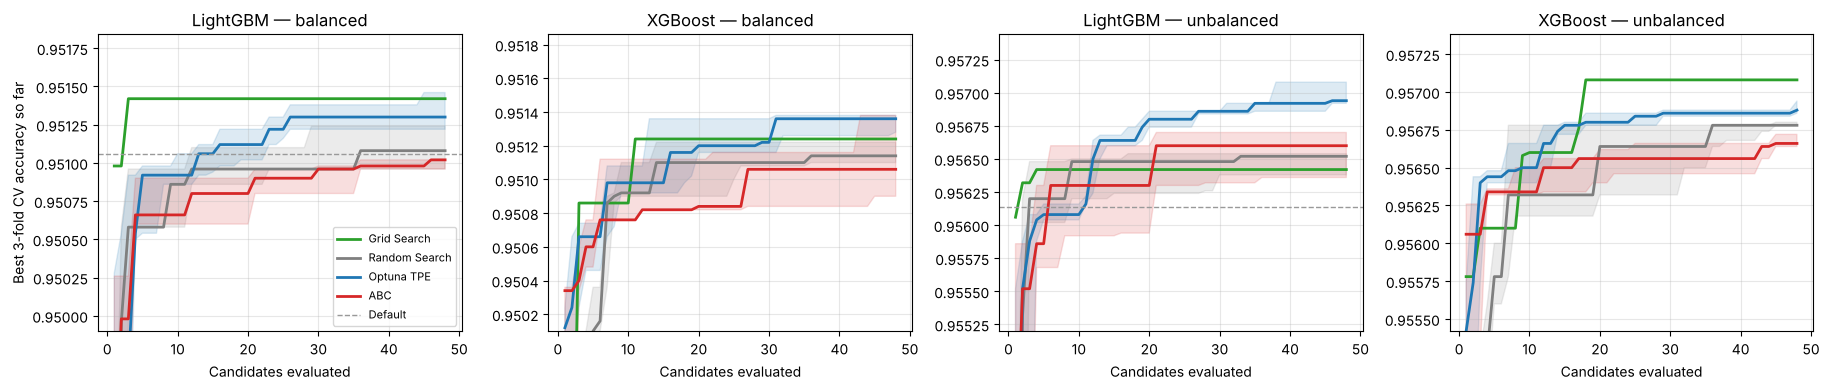

In [7]:
pairs = sorted(df.groupby(["dataset", "model"]).groups)
fig, axes = plt.subplots(1, len(pairs), figsize=(4.6 * len(pairs), 4), squeeze=False)
for ax, (ds, model) in zip(axes[0], pairs):
    g = df[(df.dataset == ds) & (df.model == model)]
    for m in METHODS[1:]:
        runs = [np.maximum.accumulate(r) for r in g[g.method == m].cv_scores]
        if not runs: continue
        c = np.array(runs); x = np.arange(1, c.shape[1] + 1)
        ax.plot(x, np.median(c, 0), color=COLORS[m], lw=2, label=m)
        if len(runs) > 1:
            ax.fill_between(x, *np.percentile(c, [25, 75], 0), color=COLORS[m], alpha=0.15)
    d = g[g.method == "Default"].best_cv
    if len(d): ax.axhline(d.iloc[0], color="#999999", ls="--", lw=1, label="Default")
    vals = np.concatenate([np.maximum.accumulate(r)[8:] for r in g.cv_scores if len(r) > 8])
    ax.set_ylim(np.percentile(vals, 1) - 0.0005, vals.max() + 0.0003)
    ax.set_title(f"{model} — {ds}"); ax.set_xlabel("Candidates evaluated"); ax.grid(alpha=0.3)
axes[0][0].set_ylabel("Best 3-fold CV accuracy so far"); axes[0][0].legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig("figures/convergence.png", dpi=150, bbox_inches="tight"); plt.show()

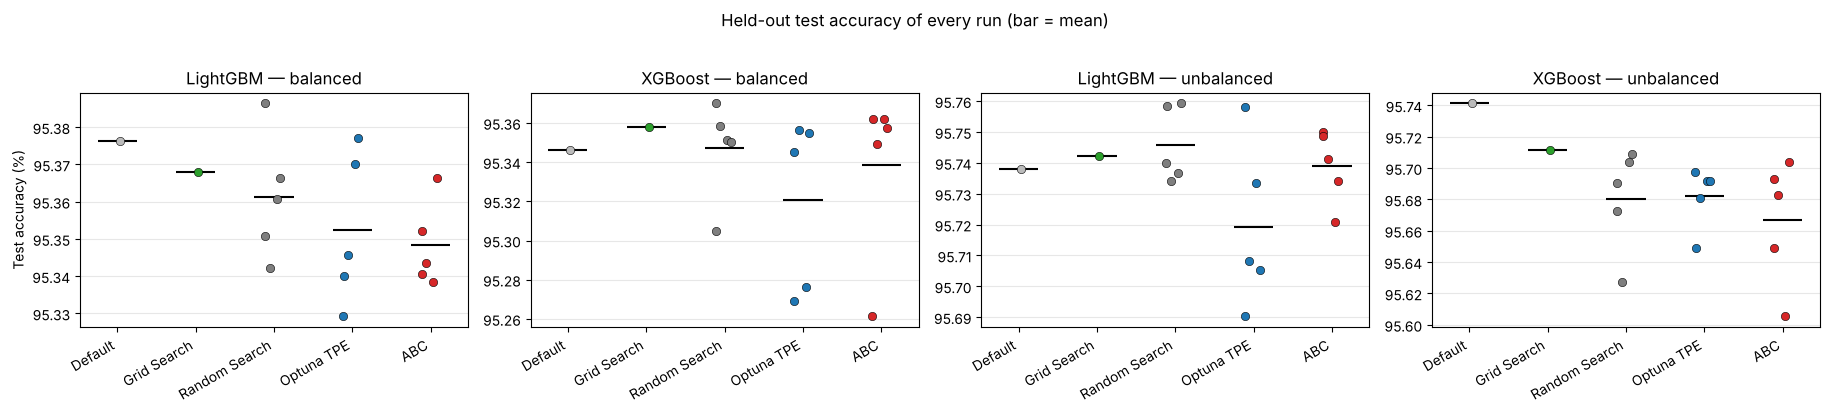

In [8]:
fig, axes = plt.subplots(1, len(pairs), figsize=(4.6 * len(pairs), 4), squeeze=False)
for ax, (ds, model) in zip(axes[0], pairs):
    g = df[(df.dataset == ds) & (df.model == model)]
    for i, m in enumerate(METHODS):
        v = 100 * g[g.method == m].test_accuracy
        ax.scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-0.12, 0.12, len(v)), v,
                   color=COLORS[m], s=36, edgecolor="k", linewidth=0.4, zorder=3)
        if len(v): ax.hlines(v.mean(), i - 0.25, i + 0.25, color="k", lw=1.5)
    ax.set_xticks(range(len(METHODS))); ax.set_xticklabels(METHODS, rotation=30, ha="right")
    ax.set_title(f"{model} — {ds}"); ax.grid(axis="y", alpha=0.3)
axes[0][0].set_ylabel("Test accuracy (%)")
fig.suptitle("Held-out test accuracy of every run (bar = mean)", y=1.02)
fig.tight_layout(); fig.savefig("figures/test_accuracy.png", dpi=150, bbox_inches="tight"); plt.show()

## Sensitivity check: is photon-level splitting leaking information?

The data has no event IDs, so train and test can contain photons from the same simulated event. The unbalanced file is stored in simulation order, so a split into **contiguous blocks** keeps most events on one side. `leakage_check.py` compares both splits with default models.

In [9]:
print(pd.read_csv("results/leakage_check.csv").round(5).to_markdown(index=False))

| Split                      | Model    |   Test accuracy |   Std over folds |
|:---------------------------|:---------|----------------:|-----------------:|
| Random (stratified)        | XGBoost  |         0.95741 |        nan       |
| Random (stratified)        | LightGBM |         0.95738 |        nan       |
| Contiguous blocks (5-fold) | XGBoost  |         0.95739 |          0.00027 |
| Contiguous blocks (5-fold) | LightGBM |         0.95735 |          0.00019 |


## Discussion

ABC runs use **abcopt 0.2.1**, which reproduces the Erciyes University reference implementation of the canonical ABC step for step (verified by a trajectory-equivalence test in the abcopt repository).

**1. Machine learning clearly beats the classical time cut.** Every gradient-boosted model reaches about 95.4% (balanced) and 95.7% (unbalanced) test accuracy, against 91.6% and 92.0% for the best single time threshold: a gain of roughly **3.8 percentage points**. On the unbalanced set, F1 rises from 0.869 to 0.929.

**2. Hyperparameter tuning hardly matters on this problem.** Every tuned model ends within 0.08 points of the default settings, and no tuner improves on the defaults by more than about 0.01 points. The landscape is flat: 36–49% of uniformly random configurations lie within 0.25 points of the best CV score ever found. With only three photon-level features (hit time, energy, PMT number), accuracy is limited by how much the two light populations overlap in feature space, not by the classifier's settings. For XGBoost on the unbalanced set, the defaults are even slightly better than every tuned model: settings chosen on a 50,000-photon subsample do not fully transfer to a model trained on 930,000 photons.

**3. No tuner generalises better than another.** Optuna TPE reaches the highest CV score during search in most settings and is significantly ahead of ABC on that objective in two of them (p = 0.016). On the held-out test set, however, no difference between ABC, Random Search and TPE is significant (all p ≥ 0.22), and the ranking changes from one setting to the next. Winning the search objective does not translate into better test performance when the landscape is this flat and the CV estimate is this noisy.

An earlier run with abcopt 0.2.0, whose onlooker probabilities followed `fit_i / Σ fit` instead of the reference code's `0.9 · fit_i / max(fit) + 0.1`, had suggested that ABC generalises slightly better than TPE. With the reference-exact implementation this effect disappears, so it should be read as noise, not as a property of ABC (the earlier results are kept in `results/v0.2.0/`).

**4. Results are not inflated by splitting photons from the same event.** Contiguous-block splits, which keep most events on one side of the split, give the same accuracy as random splits to within 0.005 points.

### Limitations

- A single train/test split, three features and a 48-candidate budget per run.
- The search uses a 50,000-photon subsample; tuning on more data (or with multi-fidelity methods) may change the picture for the larger training set.
- Five seeds per stochastic method; with 5 vs 5 runs the smallest attainable p-value is 0.008, and no correction for multiple comparisons is applied.

### Take-away

For Cherenkov/scintillation separation with photon-level features, the remaining room for improvement lies in **more informative inputs** (for example event-level context or neighbouring hits) rather than in hyperparameter optimisation. Since compact, readable decision rules may approach the same ceiling, this motivates the interpretable-algorithm-discovery direction of the KOVAN project.
